# EDA — Siniestros Viales de Bogotá D.C. (Unión de fuentes)

Este cuaderno une y analiza dos fuentes de datos abiertos sobre siniestralidad vial en Bogotá D.C.:

1. **`DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx`** — archivo oficial "Datos Abiertos" con 5 hojas relacionales: `SINIESTROS`, `ACTOR_VIAL`, `VEHICULOS`, `HIPOTESIS` y `DICCIONARIO` (codificación de valores).
2. **`historico_siniestros_bogota_d_c_-.csv`** — histórico consolidado de siniestros con coordenadas geográficas (`LATITUD`, `LONGITUD`).

Ambas fuentes comparten la llave **`CODIGO_ACCIDENTE`**, que identifica un siniestro. Se usa para:
- Unir el histórico georreferenciado (CSV) con el detalle oficial del siniestro (hoja `SINIESTROS`).
- Enriquecer cada siniestro con información agregada de actores viales, vehículos involucrados y causas (hipótesis), agregadas desde las otras hojas del Excel.

Estructura del cuaderno:

1. Diccionario de variables (CSV y cada hoja del Excel)
2. Carga de datos
3. Preparación y unión de los datasets por `CODIGO_ACCIDENTE`
4. EDA general del dataset unido
5. Análisis temporal
6. Análisis por gravedad, clase, causas y actores
7. Mapa de zonas con accidentes
8. Resumen y hallazgos clave


## 1. Diccionario de variables

### 1.1 `historico_siniestros_bogota_d_c_-.csv`

199.146 registros. Un registro = un siniestro georreferenciado.

| Variable | Tipo | Descripción |
|---|---|---|
| `X` | float | Coordenada X (idéntica a `LONGITUD`), grados decimales EPSG:4326. |
| `Y` | float | Coordenada Y (idéntica a `LATITUD`), grados decimales EPSG:4326. |
| `OBJECTID` | int | Identificador interno del registro en el sistema de origen. |
| `FORMULARIO` | str | Número del formulario / acta policial (FURIPS/IPAT) asociado al siniestro. |
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** Identificador único del siniestro, compartido con el archivo Excel. |
| `FECHA_OCURRENCIA_ACC` | str/fecha | Fecha en que ocurrió el siniestro. |
| `ANO_OCURRENCIA_ACC` | int | Año de ocurrencia (2015–2021). |
| `DIRECCION` | str | Dirección / nomenclatura vial donde ocurrió el siniestro. |
| `GRAVEDAD` | str | Gravedad del siniestro: `SOLO DAÑOS`, `CON HERIDOS`, `CON MUERTOS`. |
| `CLASE_ACC` | str | Clase de siniestro: `CHOQUE`, `ATROPELLO`, `CAIDA DE OCUPANTE`, `VOLCAMIENTO`, `OTRO`, `INCENDIO`, `AUTOLESION`. |
| `LOCALIDAD` | str | Localidad de Bogotá donde ocurrió el siniestro (46 nulos). |
| `FECHA_HORA_ACC` | str/fecha-hora | Fecha y hora completa del siniestro. |
| `LATITUD` | float | Latitud del siniestro (EPSG:4326). |
| `LONGITUD` | float | Longitud del siniestro (EPSG:4326). |
| `CIV` | float | Código de Identificación Vial del segmento donde ocurrió (1.701 nulos). |
| `PK_CALZADA` | float | Punto kilométrico sobre la calzada (37.974 nulos, alta tasa de faltantes). |

### 1.2 `SINIESTROS` (hoja del Excel)

196.152 registros. Nivel de detalle: un siniestro. Los códigos se decodifican usando la hoja `DICCIONARIO` del mismo archivo.

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión** con el CSV. |
| `FECHA` | str/fecha | Fecha de ocurrencia. |
| `HORA` | str | Hora de ocurrencia. |
| `GRAVEDAD` | int | Código de gravedad: `1`=Con Muertos, `2`=Con Heridos, `3`=Solo Daños. |
| `CLASE` | int | Código de clase de siniestro: `1`=Choque, `2`=Atropello, `3`=Volcamiento, `4`=Caída de ocupante, `5`=Incendio, `6`=Otro, `7`=Autolesión. |
| `CHOQUE` | float | Tipo de objeto contra el que se chocó (solo aplica si `CLASE`=Choque): `1`=Vehículo, `2`=Tren, `3`=Semoviente, `4`=Objeto Fijo. |
| `OBJETO_FIJO` | float | Detalle del objeto fijo golpeado (solo si `CHOQUE`=4): Muro, Poste, Árbol, Barandas, Semáforo, Inmueble, Hidrante, Valla/Señal, Tarima/Caseta, Vehículo estacionado, Otro. |
| `DIRECCION` | str | Dirección del siniestro. |
| `CODIGO_LOCALIDAD` | int | Código numérico de la localidad (1–20, incluye Sumapaz). |
| `DISENO_LUGAR` | int | Diseño del lugar donde ocurrió: Tramo de Vía, Intersección, Vía peatonal, Paso elevado/inferior/a nivel, Glorieta, Puente, Vía troncal, Lote/predio, Ciclorruta, Pontón, Túnel. |

### 1.3 `ACTOR_VIAL` (hoja del Excel)

422.417 registros. Nivel de detalle: una persona involucrada en un siniestro (varias por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** que vincula al siniestro. |
| `CODIGO_ACCIDENTADO` | int | Identificador de la persona involucrada. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CONDICION` | str | Rol de la persona: `CONDUCTOR`, `MOTOCICLISTA`, `PASAJERO/ACOMPAÑANTE`, `PEATON`, `CICLISTA`. |
| `ESTADO` | str | Estado de la persona tras el siniestro: `ILESO`, `HERIDO`, `MUERTO`. |
| `EDAD` | object | Edad de la persona (contiene inconsistencias de formato, se trata como texto en la fuente). |
| `SEXO` | str | Sexo reportado: `MASCULINO`, `FEMENINO`, `SIN INFORMACION`. |
| `VEHICULO` | str | Código del vehículo asociado (nulo para peatones — 23.447 nulos, coincide con el conteo de peatones). |

### 1.4 `VEHICULOS` (hoja del Excel)

371.606 registros. Nivel de detalle: un vehículo involucrado en un siniestro (varios por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `VEHICULO` | str | Identificador del vehículo (formato `CODIGO_ACCIDENTE-n`). |
| `CLASE` | int | Clase de vehículo (27 categorías): Automóvil, Bus, Buseta, Camión/Furgón, Camioneta, Campero, Microbús, Motocicleta, Bicicleta, Bus Articulado, entre otros. |
| `SERVICIO` | int | Tipo de servicio del vehículo: `1`=Oficial, `2`=Público, `3`=Particular, `4`=Diplomático, `0`=Sin información. |
| `MODALIDAD` | int | Modalidad de transporte (Mixto, Carga, Pasajeros — Masivo/Colectivo/Individual/Escolar, etc.). |
| `ENFUGA` | str | Indica si el vehículo se dio a la fuga: `S`/`N`. |

### 1.5 `HIPOTESIS` (hoja del Excel)

233.820 registros. Nivel de detalle: una causa/hipótesis asociada a un siniestro (varias posibles por `CODIGO_ACCIDENTE`).

| Variable | Tipo | Descripción |
|---|---|---|
| `CODIGO_ACCIDENTE` | int | **Llave de unión.** que vincula al siniestro. |
| `FECHA` | str/fecha | Fecha del siniestro. |
| `CODIGO_CAUSA` | int | Código de causa probable del siniestro (~150 categorías agrupadas por actor: conductor en general, ciclista/motociclista, vehículo, vía, peatón, pasajero/acompañante). Ej.: `116`=Exceso de velocidad, `115`=Embriaguez o droga, `142`=Semáforo en rojo, `306`=Huecos, `409`=Cruzar sin observar. |

### 1.6 `DICCIONARIO` (hoja del Excel)

212 filas. Tabla de codificación oficial: `HOJA`, `CAMPO`, `CODIGO`, `DESCRIPCION`. Se usa programáticamente en este cuaderno para traducir todos los códigos numéricos anteriores a sus etiquetas de texto.


## 2. Carga de librerías y datos

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
import re
import seaborn as sns
import scipy as sp
import geopandas as gpd

pd.set_option('display.max_columns', 60)
plt.rcParams['figure.figsize'] = (9, 6)

from scipy.stats import chi2_contingency, kruskal


In [2]:
FILE_XLSX = "Data/raw/DATO_ABIERTOS_siniestros_viales_consolidados_bogota_dc (3).xlsx"
FILE_CSV = "Data/raw/historico_siniestros_bogota_d_c_-.csv"

# Histórico georreferenciado
hist = pd.read_csv(FILE_CSV, encoding='utf-8-sig')

# Hojas del archivo oficial
siniestros = pd.read_excel(FILE_XLSX, sheet_name='SINIESTROS')
actor_vial = pd.read_excel(FILE_XLSX, sheet_name='ACTOR_VIAL')
vehiculos  = pd.read_excel(FILE_XLSX, sheet_name='VEHICULOS')
hipotesis  = pd.read_excel(FILE_XLSX, sheet_name='HIPOTESIS')
diccionario = pd.read_excel(FILE_XLSX, sheet_name='DICCIONARIO')

print("historico_siniestros (CSV):", hist.shape)
print("SINIESTROS   :", siniestros.shape)
print("ACTOR_VIAL   :", actor_vial.shape)
print("VEHICULOS    :", vehiculos.shape)
print("HIPOTESIS    :", hipotesis.shape)
print("DICCIONARIO  :", diccionario.shape)


historico_siniestros (CSV): (199146, 16)
SINIESTROS   : (196152, 10)
ACTOR_VIAL   : (422416, 8)
VEHICULOS    : (371605, 7)
HIPOTESIS    : (233819, 3)
DICCIONARIO  : (211, 4)


### 2.1 Vista previa de cada tabla

In [3]:
vehiculos.head()

,CODIGO_ACCIDENTE,FECHA,VEHICULO,CLASE,SERVICIO,MODALIDAD,ENFUGA
0,4401423,01/01/2015,4401423-1,1.0,2.0,5.0,N
1,4401423,01/01/2015,4401423-2,1.0,3.0,NaN,N
2,4401420,01/01/2015,4401420-1,1.0,2.0,5.0,N
3,4401420,01/01/2015,4401420-2,1.0,3.0,NaN,N
4,4401429,01/01/2015,4401429-1,7.0,2.0,4.0,N


In [4]:
actor_vial.head()

,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO
0,4401447,2452576,01/01/2015,CONDUCTOR,ILESO,44,FEMENINO,4401447-1
1,4401447,2452577,01/01/2015,CONDUCTOR,ILESO,31,MASCULINO,4401447-2
2,4401453,2452586,01/01/2015,CONDUCTOR,ILESO,47,MASCULINO,4401453-1
3,4401453,2452587,01/01/2015,CONDUCTOR,ILESO,29,MASCULINO,4401453-2
4,4401423,2452500,01/01/2015,CONDUCTOR,HERIDO,44,MASCULINO,4401423-1


In [5]:
hist.head()

,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0


In [6]:
siniestros.head()

,CODIGO_ACCIDENTE,FECHA,HORA,GRAVEDAD,CLASE,CHOQUE,OBJETO_FIJO,DIRECCION,CODIGO_LOCALIDAD,DISENO_LUGAR
0,4401438,01/01/2015,01:05:00,2,2,NaN,NaN,KR 64A-CL 2C 02,16,2
1,4401449,01/01/2015,05:50:00,2,3,NaN,NaN,AV AVENIDA DEL SUR-KR 65A 41,7,1
2,4401430,01/01/2015,07:15:00,2,3,NaN,NaN,KR 19D-CL 62 S 02,19,1
3,4401453,01/01/2015,09:30:00,3,1,1.0,NaN,KR 79-CL 42F S 71,8,1
4,4401423,01/01/2015,09:45:00,2,1,1.0,NaN,CL 66A-KR 76 02,10,2


In [7]:
siniestros.head()

,CODIGO_ACCIDENTE,FECHA,HORA,GRAVEDAD,CLASE,CHOQUE,OBJETO_FIJO,DIRECCION,CODIGO_LOCALIDAD,DISENO_LUGAR
0,4401438,01/01/2015,01:05:00,2,2,NaN,NaN,KR 64A-CL 2C 02,16,2
1,4401449,01/01/2015,05:50:00,2,3,NaN,NaN,AV AVENIDA DEL SUR-KR 65A 41,7,1
2,4401430,01/01/2015,07:15:00,2,3,NaN,NaN,KR 19D-CL 62 S 02,19,1
3,4401453,01/01/2015,09:30:00,3,1,1.0,NaN,KR 79-CL 42F S 71,8,1
4,4401423,01/01/2015,09:45:00,2,1,1.0,NaN,CL 66A-KR 76 02,10,2


In [8]:
diccionario.head(10)

,HOJA,CAMPO,CODIGO,DESCRIPCION
0,SINIESTROS,GRAVEDAD,1,Con Muertos
1,SINIESTROS,GRAVEDAD,2,Con Heridos
2,SINIESTROS,GRAVEDAD,3,Solo Daños
3,SINIESTROS,CLASE,7,Autolesion
4,SINIESTROS,CLASE,1,Choque
5,SINIESTROS,CLASE,2,Atropello
6,SINIESTROS,CLASE,4,Caida de ocupante
7,SINIESTROS,CLASE,3,Volcamiento
8,SINIESTROS,CLASE,6,Otro
9,SINIESTROS,CLASE,5,Incendio


### Entendimiento de actor vial.

In [9]:
actor_vial["CONDICION"].value_counts()

CONDICION
CONDUCTOR               306534
MOTOCICLISTA             52290
PASAJERO/ACOMPAÑANTE     27365
PEATON                   23447
CICLISTA                 12780
Name: count, dtype: int64

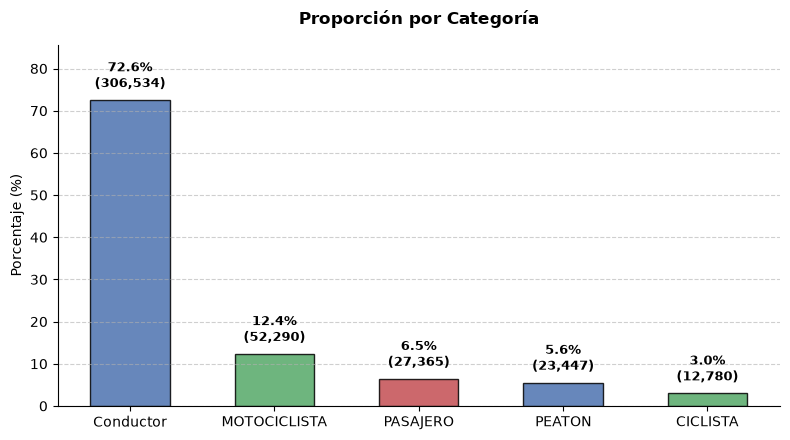

In [10]:
categorias = ['Conductor','MOTOCICLISTA','PASAJERO','PEATON','CICLISTA']
conteos = actor_vial['CONDICION'].value_counts()
porcentajes = actor_vial['CONDICION'].value_counts(normalize=True) * 100
colores = ['#4C72B0', '#55A868', '#C44E52']

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(categorias, porcentajes, color=colores, edgecolor='black', alpha=0.85, width=0.55)

# Agregar el porcentaje y conteo exacto sobre cada barra
for bar, count in zip(bars, conteos):
    pct = bar.get_height()
    ax.annotate(f'{pct:.1f}%\n({count:,})',
                xy=(bar.get_x() + bar.get_width() / 2, pct),
                xytext=(0, 6),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax.set_title('Proporción por Categoría', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('Porcentaje (%)', fontsize=10)
ax.set_ylim(0, max(porcentajes) * 1.18)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Ocultar bordes superior y derecho
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

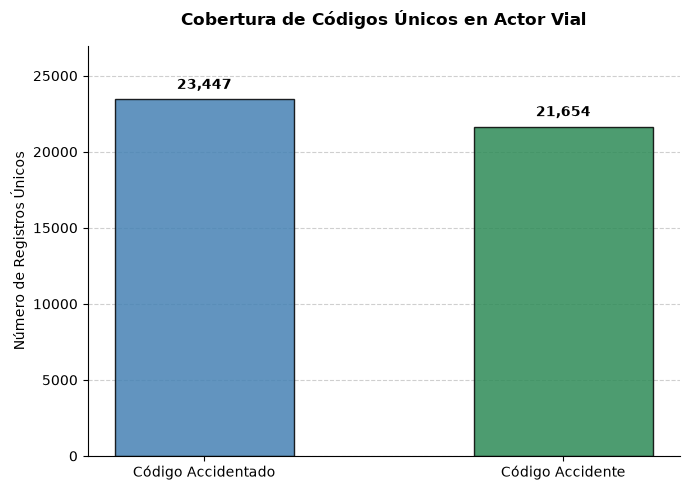

In [11]:
peatonal = actor_vial[actor_vial["CONDICION"] == "PEATON"]

# 1. Calcular el conteo de valores únicos (únicos reales)
val_accidentado = peatonal["CODIGO_ACCIDENTADO"].nunique()
val_accidente = peatonal["CODIGO_ACCIDENTE"].nunique()

labels = ['Código Accidentado', 'Código Accidente']
valores = [val_accidentado, val_accidente]
colores = ['steelblue', 'seagreen']

# 2. Crear la figura
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_axisbelow(True)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# 3. Graficar las barras (2 colores para 2 barras)
bars = ax.bar(labels, valores, color=colores, edgecolor='black', alpha=0.85, width=0.5)

# 4. Anotar el conteo exacto sobre cada barra
for i, v in enumerate(valores):
    ax.text(i, v + (max(valores) * 0.02), f"{v:,}", ha='center', va='bottom', fontweight='bold', fontsize=10)

# 5. Personalizar títulos y límites
ax.set_title('Cobertura de Códigos Únicos en Actor Vial', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('Número de Registros Únicos', fontsize=10)
ax.set_ylim(0, max(valores) * 1.15)  # Margen superior para las etiquetas

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

#### Se observa que existen casos donde para un mismo accidente afecto a mas de un peaton.

In [12]:
# Filtra todas las filas cuyo CODIGO_ACCIDENTE aparece 2 o más veces
duplicados = peatonal[peatonal.duplicated(subset=['CODIGO_ACCIDENTE'], keep=False)]

# Ordenar por CODIGO_ACCIDENTE para ver las repeticiones agrupadas
duplicados = duplicados.sort_values(by='CODIGO_ACCIDENTE')

print(f"Total de filas duplicadas: {len(duplicados)}")
print(f"Cantidad de códigos únicos repetidos: {duplicados['CODIGO_ACCIDENTE'].nunique()}")

# Mostrar los primeros registros duplicados
duplicados

Total de filas duplicadas: 3329
Cantidad de códigos únicos repetidos: 1536


,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO
114,4401421,2452502,02/01/2015,PEATON,HERIDO,17,MASCULINO,NaN
115,4401421,2452503,02/01/2015,PEATON,HERIDO,25,FEMENINO,NaN
1088,4401915,2453581,10/01/2015,PEATON,MUERTO,50,MASCULINO,NaN
1089,4401915,2453582,10/01/2015,PEATON,HERIDO,45,MASCULINO,NaN
1237,4401921,2453601,12/01/2015,PEATON,HERIDO,38,FEMENINO,NaN
...,...,...,...,...,...,...,...,...
421694,10530004,12727799,26/12/2020,PEATON,HERIDO,21,MASCULINO,NaN
421693,10530004,12727798,26/12/2020,PEATON,HERIDO,25,MASCULINO,NaN
421692,10530004,12727797,26/12/2020,PEATON,HERIDO,22,MASCULINO,NaN
413813,10533627,12735589,10/11/2020,PEATON,HERIDO,20,FEMENINO,NaN


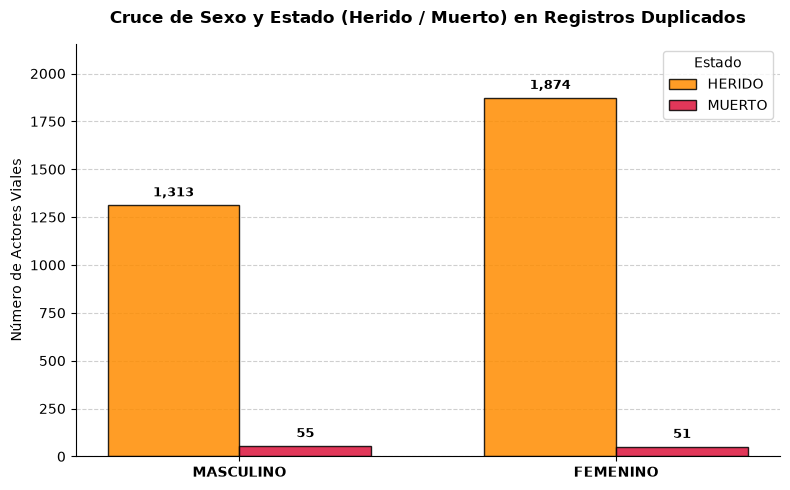

In [13]:
# 1. Crear la tabla cruzada entre SEXO y ESTADO
cruce = pd.crosstab(duplicados['SEXO'], duplicados['ESTADO'])

# Seleccionar explícitamente las columnas de interés en caso de que existan otros valores
cruce = cruce.reindex(columns=['HERIDO', 'MUERTO'], fill_value=0)
cruce = cruce.reindex(index=['MASCULINO', 'FEMENINO'], fill_value=0)

# 2. Graficar
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_axisbelow(True)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Ancho de las barras y posiciones
x = range(len(cruce.index))
width = 0.35

bars1 = ax.bar([p - width/2 for p in x], cruce['HERIDO'], width=width, label='HERIDO', color='darkorange', edgecolor='black', alpha=0.85)
bars2 = ax.bar([p + width/2 for p in x], cruce['MUERTO'], width=width, label='MUERTO', color='crimson', edgecolor='black', alpha=0.85)

# 3. Anotar valores exactos sobre cada barra
for bar in bars1 + bars2:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{height:,}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# 4. Personalización del gráfico
ax.set_title('Cruce de Sexo y Estado (Herido / Muerto) en Registros Duplicados', fontsize=12, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(cruce.index, fontweight='bold')
ax.set_ylabel('Número de Actores Viales', fontsize=10)
ax.set_ylim(0, cruce.values.max() * 1.15)
ax.legend(title='Estado', frameon=True)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## 3. Preparación y unión de los datasets

### 3.1 Función de decodificación

Se construye un diccionario Python `{{(HOJA, CAMPO): {{codigo: descripcion}}}}` a partir de la hoja `DICCIONARIO`, para traducir los códigos numéricos de `SINIESTROS`, `VEHICULOS` e `HIPOTESIS` a texto legible.

In [14]:
def construir_mapa_diccionario(dicc):
    mapa = {}
    for _, row in dicc.iterrows():
        clave = (row['HOJA'], row['CAMPO'])
        mapa.setdefault(clave, {})[row['CODIGO']] = row['DESCRIPCION']
    return mapa

mapa_dicc = construir_mapa_diccionario(diccionario)

def decodificar(df, hoja, campo, nueva_col=None):
    nueva_col = nueva_col or f"{campo}_DESC"
    mapa = mapa_dicc.get((hoja, campo), {})
    df[nueva_col] = df[campo].map(mapa)
    return df

# Decodificar SINIESTROS
siniestros = decodificar(siniestros, 'SINIESTROS', 'GRAVEDAD')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CLASE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CHOQUE')
siniestros = decodificar(siniestros, 'SINIESTROS', 'OBJETO_FIJO')
siniestros = decodificar(siniestros, 'SINIESTROS', 'CODIGO_LOCALIDAD', 'LOCALIDAD_DESC')
siniestros = decodificar(siniestros, 'SINIESTROS', 'DISENO_LUGAR')

# Decodificar VEHICULOS
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'CLASE')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'SERVICIO')
vehiculos = decodificar(vehiculos, 'VEHICULOS', 'MODALIDAD')

# Decodificar HIPOTESIS
hipotesis = decodificar(hipotesis, 'HIPOTESIS', 'CODIGO_CAUSA')

siniestros[['GRAVEDAD','GRAVEDAD_DESC','CLASE','CLASE_DESC','DISENO_LUGAR','DISENO_LUGAR_DESC']].head()

,GRAVEDAD,GRAVEDAD_DESC,CLASE,CLASE_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,2,Con Heridos,2,Atropello,2,Interseccion
1,2,Con Heridos,3,Volcamiento,1,Tramo de Via
2,2,Con Heridos,3,Volcamiento,1,Tramo de Via
3,3,Solo Daños,1,Choque,1,Tramo de Via
4,2,Con Heridos,1,Choque,2,Interseccion


### 3.2 Cobertura de la llave `CODIGO_ACCIDENTE` entre fuentes

Antes de unir, se revisa cuántos códigos coinciden entre el CSV histórico y la hoja `SINIESTROS` del Excel.

In [15]:
set_csv = set(hist['CODIGO_ACCIDENTE'])
set_xlsx = set(siniestros['CODIGO_ACCIDENTE'])

interseccion = set_csv & set_xlsx
solo_csv = set_csv - set_xlsx
solo_xlsx = set_xlsx - set_csv

print(f"Códigos únicos en CSV               : {len(set_csv):,}")
print(f"Códigos únicos en SINIESTROS (XLSX)  : {len(set_xlsx):,}")
print(f"En ambas fuentes (intersección)      : {len(interseccion):,}")
print(f"Solo en CSV (sin match en XLSX)      : {len(solo_csv):,}")
print(f"Solo en XLSX (sin match en CSV)      : {len(solo_xlsx):,}")

Códigos únicos en CSV               : 199,146
Códigos únicos en SINIESTROS (XLSX)  : 196,152
En ambas fuentes (intersección)      : 181,020
Solo en CSV (sin match en XLSX)      : 18,126
Solo en XLSX (sin match en CSV)      : 15,132


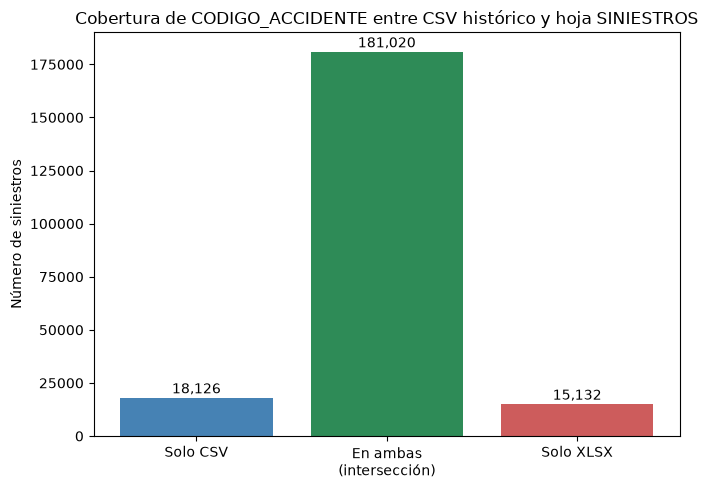

In [16]:
fig, ax = plt.subplots(figsize=(7,5))
labels = ['Solo CSV', 'En ambas\n(intersección)', 'Solo XLSX']
valores = [len(solo_csv), len(interseccion), len(solo_xlsx)]
ax.bar(labels, valores, color=['steelblue', 'seagreen', 'indianred'])
for i, v in enumerate(valores):
    ax.text(i, v + 2000, f"{v:,}", ha='center')
ax.set_title('Cobertura de CODIGO_ACCIDENTE entre CSV histórico y hoja SINIESTROS')
ax.set_ylabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 3.3 Unión principal (CSV + SINIESTROS)

Se agregan, por `CODIGO_ACCIDENTE`, resúmenes de las otras tres hojas y se incorporan al dataset unido:
- **Actores viales**: número de personas involucradas, número de muertos/heridos, sexo predominante.
- **Vehículos**: número de vehículos involucrados, clase de vehículo más frecuente.
- **Hipótesis**: causa principal reportada (la primera registrada por siniestro).

In [17]:
cols_siniestros = ['CODIGO_ACCIDENTE', 'CHOQUE', 'CHOQUE_DESC', 'OBJETO_FIJO', 'OBJETO_FIJO_DESC',
                    'DISENO_LUGAR', 'DISENO_LUGAR_DESC']

df_total = hist.merge(siniestros[cols_siniestros], on='CODIGO_ACCIDENTE', how='left', indicator=True)

print("Registros del CSV con match en SINIESTROS:", (df_total['_merge'] == 'both').sum())
print("Registros del CSV SIN match en SINIESTROS:", (df_total['_merge'] == 'left_only').sum())
df_total = df_total.drop(columns='_merge')
print("\nShape del dataset unido:", df_total.shape)
df_total.head()

Registros del CSV con match en SINIESTROS: 181020
Registros del CSV SIN match en SINIESTROS: 18126

Shape del dataset unido: (199146, 22)


,X,Y,OBJECTID,FORMULARIO,CODIGO_ACCIDENTE,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,DIRECCION,GRAVEDAD,CLASE_ACC,LOCALIDAD,FECHA_HORA_ACC,LATITUD,LONGITUD,CIV,PK_CALZADA,CHOQUE,CHOQUE_DESC,OBJETO_FIJO,OBJETO_FIJO_DESC,DISENO_LUGAR,DISENO_LUGAR_DESC
0,-74.090924,4.693807,1,A000640275,4484660,2017/06/12 00:00:00+00,2017,AV AVENIDA BOYACA-CL 79 02,SOLO DANOS,CHOQUE,ENGATIVA,2017/06/12 05:30:00+00,4.693807,-74.090924,10006772.0,221236.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
1,-74.121000,4.603000,2,A001233353,10533499,2020/11/19 00:00:00+00,2020,CL 26 S- KR 50 02,CON HERIDOS,OTRO,PUENTE ARANDA,2020/11/19 02:05:00+00,4.603000,-74.121000,16004560.0,NaN,NaN,NaN,NaN,NaN,7.0,Glorieta
2,-74.042000,4.682000,4,A001232786,10533629,2020/11/10 00:00:00+00,2020,KR 9 - CL 100 02,SOLO DANOS,CHOQUE,USAQUEN,2020/11/10 13:30:00+00,4.682000,-74.042000,30001107.0,NaN,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
3,-74.166937,4.587187,7,A000200705,4412699,2015/05/11 00:00:00+00,2015,CL 63A-KR 72 S 02,SOLO DANOS,CHOQUE,CIUDAD BOLIVAR,2015/05/11 10:50:00+00,4.587187,-74.166937,19001483.0,136166.0,1.0,Vehiculo,NaN,NaN,1.0,Tramo de Via
4,-74.092901,4.607648,8,A000402862,4447845,2016/06/08 00:00:00+00,2016,KR 27-CL 9 14,SOLO DANOS,CHOQUE,LOS MARTIRES,2016/06/08 21:30:00+00,4.607648,-74.092901,14000548.0,239719.0,1.0,Vehiculo,NaN,NaN,5.0,Paso inferior


### 3.4 Enriquecimiento con actores, vehículos y causas

Se agregan, por `CODIGO_ACCIDENTE`, resúmenes de las otras tres hojas y se incorporan al dataset unido:
- **Actores viales**: número de personas involucradas, número de muertos/heridos, sexo predominante.
- **Vehículos**: número de vehículos involucrados, clase de vehículo más frecuente.
- **Hipótesis**: causa principal reportada (la primera registrada por siniestro).

Para el EDA de siniestralidad **peatonal** el criterio correcto es analizar solo los accidentes donde estuvo involucrado un peaton.
1. Filtrar `ACTOR_VIAL` a `CONDICION == 'PEATON'`.
2. Calcular las métricas (conteo, muertos, heridos, sexo) **solo** sobre esos registros.
3. Unir esa agregación al dataset general con un **inner join** por `CODIGO_ACCIDENTE`, de modo que el dataset final conserve únicamente los siniestros en los que participó **al menos un peatón** — y no la totalidad de los siniestros.


In [18]:
df = df_total.copy()
causa_principal = (
    hipotesis
    .sort_values('CODIGO_ACCIDENTE')
    .drop_duplicates('CODIGO_ACCIDENTE')
    .set_index('CODIGO_ACCIDENTE')['CODIGO_CAUSA_DESC']
    .rename('CAUSA_PRINCIPAL')
)

# 4. INFORMACIÓN INDIVIDUAL DE LOS PEATONES

peatones = actor_vial.loc[
    actor_vial['CONDICION'].eq('PEATON')
].copy()

# Edad numérica
peatones['EDAD'] = pd.to_numeric(
    peatones['EDAD'],
    errors='coerce'
)


# ============================================================
# 5. INFORMACIÓN DEL SINIESTRO
#    Se agrega a cada peatón
# ============================================================
info_siniestro = (
    siniestros[
        [
            'CODIGO_ACCIDENTE',
            'CODIGO_LOCALIDAD',
            'DISENO_LUGAR',
            'DIRECCION',
            'HORA',
            'CLASE',
        ]
    ]
    .drop_duplicates('CODIGO_ACCIDENTE')
    .set_index('CODIGO_ACCIDENTE')
)
peatones = (
    peatones
    .join(causa_principal, on='CODIGO_ACCIDENTE')
    .join(info_siniestro, on='CODIGO_ACCIDENTE')
)

info_csv = (
    df_total[
        [
            'CODIGO_ACCIDENTE',
            'LATITUD',
            'LONGITUD',
            'DISENO_LUGAR_DESC',
            'FECHA_OCURRENCIA_ACC',
            'ANO_OCURRENCIA_ACC',
            'FECHA_HORA_ACC'
        ]
    ]
    .drop_duplicates('CODIGO_ACCIDENTE')
    .set_index('CODIGO_ACCIDENTE')
)
peatones = (
    peatones
    .join(info_csv, on='CODIGO_ACCIDENTE'))

# ============================================================
# 6. ESTADÍSTICAS GENERALES
# ============================================================

n_general = df['CODIGO_ACCIDENTE'].nunique()

gravedad_general = (
    df[['CODIGO_ACCIDENTE', 'GRAVEDAD']]
    .drop_duplicates('CODIGO_ACCIDENTE')
    ['GRAVEDAD']
    .value_counts(normalize=True)
    .reindex(
        ['SOLO DANOS', 'CON HERIDOS', 'CON MUERTOS'],
        fill_value=0
    )
)


# ============================================================
# 7. DATASET FINAL A NIVEL DE PEATÓN
# ============================================================

df = peatones.copy()

n_peatonal = df['CODIGO_ACCIDENTE'].nunique()

print(
    f"Siniestros en el dataset general (todos los actores): "
    f"{n_general:,}"
)

print(
    f"Siniestros con al menos un peatón involucrado: "
    f"{n_peatonal:,}"
)

print(
    f"Porcentaje del total: "
    f"{n_peatonal / n_general * 100:.1f}%"
)

df.head()

Siniestros en el dataset general (todos los actores): 199,146
Siniestros con al menos un peatón involucrado: 21,654
Porcentaje del total: 10.9%


,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO,CAUSA_PRINCIPAL,CODIGO_LOCALIDAD,DISENO_LUGAR,DIRECCION,HORA,CLASE,LATITUD,LONGITUD,DISENO_LUGAR_DESC,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,FECHA_HORA_ACC
8,4401423,2452508,01/01/2015,PEATON,HERIDO,19.0,FEMENINO,NaN,Desobedecer señales (conductor en general),10,2,CL 66A-KR 76 02,09:45:00,1,4.684126,-74.103029,Interseccion,2015/01/01 00:00:00+00,2015.0,2015/01/01 09:45:00+00
14,4401429,2452523,01/01/2015,PEATON,HERIDO,28.0,MASCULINO,NaN,Exceso de velocidad (conductor en general),11,1,KR 91-CL 133 20,16:45:00,2,4.732433,-74.086322,Tramo de Via,2015/01/01 00:00:00+00,2015.0,2015/01/01 16:45:00+00
18,4401438,2452537,01/01/2015,PEATON,HERIDO,9.0,MASCULINO,NaN,Otra (conductor en general),16,2,KR 64A-CL 2C 02,01:05:00,2,4.621191,-74.122876,Interseccion,2015/01/01 00:00:00+00,2015.0,2015/01/01 01:05:00+00
23,4401442,2452554,01/01/2015,PEATON,HERIDO,57.0,MASCULINO,NaN,Exceso de velocidad (conductor en general),4,2,KR 1A-CL 41B ES 02,16:15:00,2,NaN,NaN,NaN,NaN,NaN,NaN
29,4401450,2452575,02/01/2015,PEATON,HERIDO,20.0,MASCULINO,NaN,Otras (peatón),19,1,DG 64ABIS-KR 17D S 02,14:30:00,2,4.554157,-74.139575,Tramo de Via,2015/01/02 00:00:00+00,2015.0,2015/01/02 14:30:00+00


In [19]:
df.describe()

,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,EDAD,CODIGO_LOCALIDAD,DISENO_LUGAR,CLASE,LATITUD,LONGITUD,ANO_OCURRENCIA_ACC
count,2.344700e+04,2.344700e+04,22902.000000,23447.000000,23447.000000,23447.000000,21893.000000,21893.000000,21893.000000
mean,6.791025e+06,6.467643e+06,39.557681,9.566597,1.261952,1.951166,4.632386,-74.113450,2017.257205
std,2.937425e+06,4.903032e+06,22.558727,5.192957,1.115276,0.397740,0.062406,0.040477,1.613435
min,4.401421e+06,2.452502e+06,0.000000,1.000000,1.000000,1.000000,4.085800,-74.228300,2015.000000
25%,4.444046e+06,2.544558e+06,21.000000,6.000000,1.000000,2.000000,4.589411,-74.143267,2016.000000
50%,4.493995e+06,2.650861e+06,36.000000,9.000000,1.000000,2.000000,4.624097,-74.112000,2017.000000
75%,1.047454e+07,1.260965e+07,57.000000,13.000000,1.000000,2.000000,4.678424,-74.084536,2019.000000
max,1.053701e+07,1.274296e+07,120.000000,19.000000,13.000000,6.000000,4.818734,-74.014053,2020.000000


### 3.5 Analisis de atipicos con limpieza de `EDAD` unica variable numerica real y variables de vulnerabilidad etaria

`EDAD` en `ACTOR_VIAL` llega como texto con formato inconsistente. Se extrae el primer número presente en la cadena (`EDAD_LIMPIA`) y se descarta lo que quede fuera de un rango plausible (0–100 años) en vez de arriesgar un dato erróneo. A partir de esta única columna limpia se construyen tanto la exploración univariada como las variables de vulnerabilidad etaria que alimentarán el dataset final.


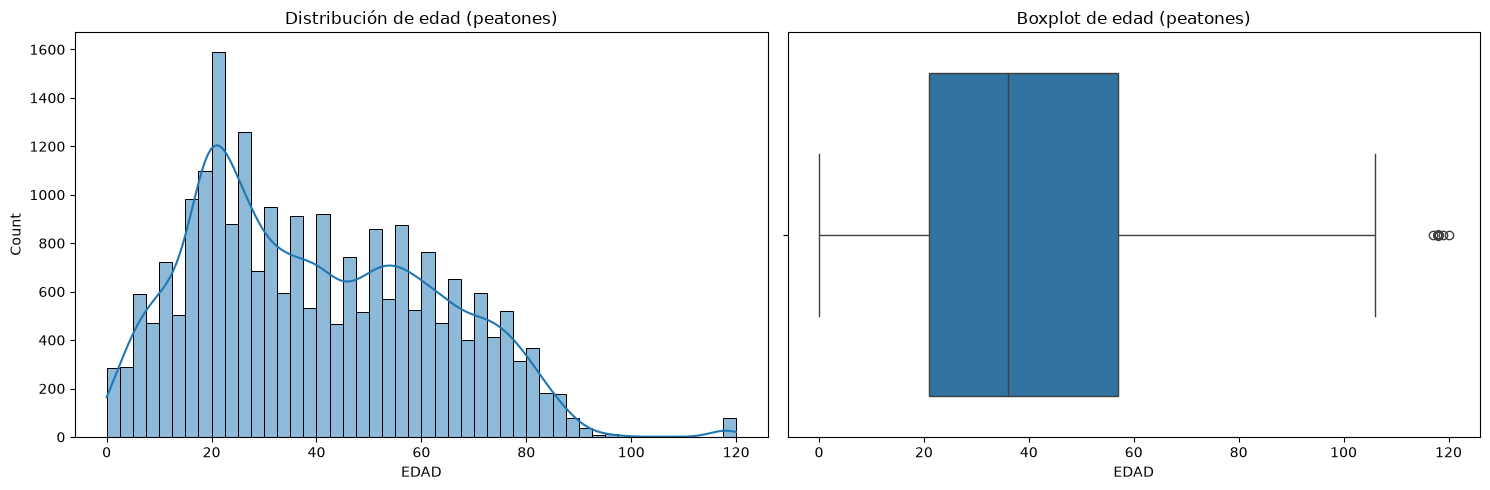

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(df['EDAD'], kde=True, ax=ax[0])
ax[0].set_title('Distribución de edad (peatones)')

sns.boxplot(x=df['EDAD'], ax=ax[1])
ax[1].set_title('Boxplot de edad (peatones)')

plt.tight_layout()
plt.show()


In [21]:
edad_atipicos = df[df["EDAD"] > 100 ]
edad_atipicos

,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO,CAUSA_PRINCIPAL,CODIGO_LOCALIDAD,DISENO_LUGAR,DIRECCION,HORA,CLASE,LATITUD,LONGITUD,DISENO_LUGAR_DESC,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,FECHA_HORA_ACC
134151,4464565,2587829,20/11/2016,PEATON,HERIDO,106.0,MASCULINO,NaN,Estacionar sin seguridad (conductor en general),19,1,CL 64C-KR 17N S 12,11:10:00,2,4.553359,-74.141435,Tramo de Via,2016/11/20 00:00:00+00,2016.0,2016/11/20 11:10:00+00
203510,4497576,2658576,25/10/2017,PEATON,HERIDO,106.0,MASCULINO,NaN,Impericia en el manejo (conductor en general),18,1,CL 40-KR 22 S 2,12:50:00,2,4.578113,-74.120274,Tramo de Via,2017/10/25 00:00:00+00,2017.0,2017/10/25 12:50:00+00
214606,4507175,2679300,12/12/2017,PEATON,HERIDO,117.0,MASCULINO,NaN,Otra (conductor en general),3,1,KR 6-CL 1 2,14:45:00,2,4.586900,-74.080500,Tramo de Via,2017/12/12 00:00:00+00,2017.0,2017/12/12 14:45:00+00
222534,4506398,2677604,25/01/2018,PEATON,HERIDO,118.0,MASCULINO,NaN,Desobedecer señales (conductor en general),3,1,KR 14-CL 11 2,20:20:00,2,4.602114,-74.081037,Tramo de Via,2018/01/25 00:00:00+00,2018.0,2018/01/25 20:20:00+00
224504,4507394,2679803,03/02/2018,PEATON,HERIDO,118.0,MASCULINO,NaN,Otras (peatón),18,1,AV AVENIDA CARACAS-CL 45A S 2,09:50:00,2,4.572478,-74.124345,Tramo de Via,2018/02/03 00:00:00+00,2018.0,2018/02/03 09:50:00+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295280,10470335,12600618,16/12/2018,PEATON,HERIDO,118.0,FEMENINO,NaN,Semáforo en rojo (conductor en general),3,1,KR 10-CL 10 2,20:11:00,2,4.599300,-74.078700,Tramo de Via,2018/12/16 00:00:00+00,2018.0,2018/12/16 20:11:00+00
295282,10470335,12600620,16/12/2018,PEATON,MUERTO,118.0,FEMENINO,NaN,Semáforo en rojo (conductor en general),3,1,KR 10-CL 10 2,20:11:00,2,4.599300,-74.078700,Tramo de Via,2018/12/16 00:00:00+00,2018.0,2018/12/16 20:11:00+00
301416,10473184,12606753,19/01/2019,PEATON,HERIDO,118.0,MASCULINO,NaN,Reverso imprudente (conductor en general),2,1,CL 93-KR 13 2,11:00:00,2,4.675596,-74.049913,Tramo de Via,2019/01/19 00:00:00+00,2019.0,2019/01/19 11:00:00+00
348708,10495300,12654034,31/08/2019,PEATON,HERIDO,119.0,MASCULINO,NaN,Cruzar en estado de embriaguez (peatón),10,1,KR 69I-CL 69A 2,19:30:00,2,4.679890,-74.092019,Tramo de Via,2019/08/31 00:00:00+00,2019.0,2019/08/31 19:30:00+00


In [22]:
edad_atipicos["EDAD"].describe()

count     81.000000
mean     117.580247
std        2.301435
min      106.000000
25%      118.000000
50%      118.000000
75%      118.000000
max      120.000000
Name: EDAD, dtype: float64

#### Se cree que fue un error de digitacion muy posiblemente al agregar la edad sobretodo en los valores mayores de 109 se duplicaba el primer numero, por ejemplo al intentar escribir 10 se escribia 110 y asi sucesivamente, esta hipotesis no es comprobable, sin embargo los registros son validos a pesar de que tengan esta edad son filas que sirven al estudio mas aun teniendo en cuenta la cantidad de datos. Se realizara una imputacion con la media diferenciando entre hombres y mujeres. 

In [23]:
media_edad_sexo = (
    df[df['EDAD'] <= 100]
    .groupby('SEXO')['EDAD']
    .mean())

media_edad_sexo

SEXO
FEMENINO           39.293388
MASCULINO          39.333861
SIN INFORMACION    32.151786
Name: EDAD, dtype: float64

In [24]:
df.loc[df['EDAD'] > 106, 'EDAD'] = (
    df.loc[df['EDAD'] > 106, 'SEXO']
    .map(media_edad_sexo))

In [25]:
df[df["EDAD"] > 100 ]

,CODIGO_ACCIDENTE,CODIGO_ACCIDENTADO,FECHA,CONDICION,ESTADO,EDAD,SEXO,VEHICULO,CAUSA_PRINCIPAL,CODIGO_LOCALIDAD,DISENO_LUGAR,DIRECCION,HORA,CLASE,LATITUD,LONGITUD,DISENO_LUGAR_DESC,FECHA_OCURRENCIA_ACC,ANO_OCURRENCIA_ACC,FECHA_HORA_ACC
134151,4464565,2587829,20/11/2016,PEATON,HERIDO,106.0,MASCULINO,NaN,Estacionar sin seguridad (conductor en general),19,1,CL 64C-KR 17N S 12,11:10:00,2,4.553359,-74.141435,Tramo de Via,2016/11/20 00:00:00+00,2016.0,2016/11/20 11:10:00+00
203510,4497576,2658576,25/10/2017,PEATON,HERIDO,106.0,MASCULINO,NaN,Impericia en el manejo (conductor en general),18,1,CL 40-KR 22 S 2,12:50:00,2,4.578113,-74.120274,Tramo de Via,2017/10/25 00:00:00+00,2017.0,2017/10/25 12:50:00+00
263858,10455621,12569098,28/07/2018,PEATON,HERIDO,106.0,FEMENINO,NaN,Embriaguez o droga (conductor en general),11,1,KR 87B-CL 128B 20,17:45:00,2,4.721003,-74.086703,Tramo de Via,2018/07/28 00:00:00+00,2018.0,2018/07/28 17:45:00+00


C:\Users\santiago\AppData\Local\Temp\ipykernel_5584\1218784407.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_2.dropna(subset=['RANGO_EDAD']), x='RANGO_EDAD', palette='Blues_d', edgecolor='black')


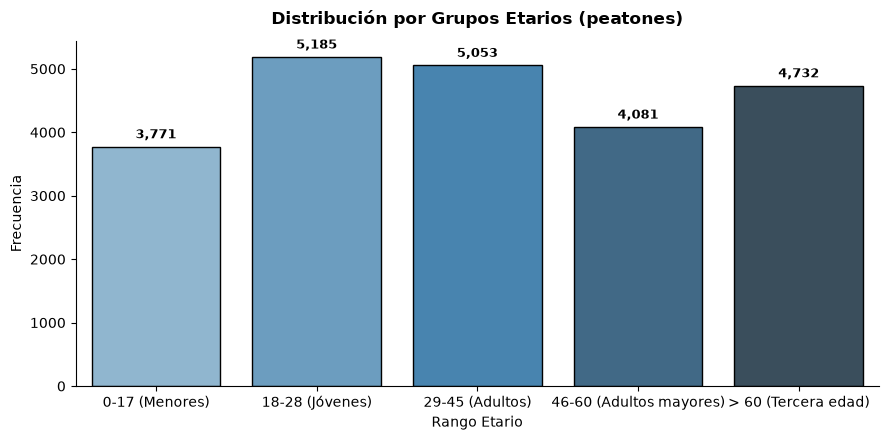

In [26]:
# Definir los grupos de edad estándar
bins = [0, 17, 28, 45, 60, 100]
labels = ['0-17 (Menores)', '18-28 (Jóvenes)', '29-45 (Adultos)', '46-60 (Adultos mayores)', '> 60 (Tercera edad)']
df_2 = pd.DataFrame()
# Crear la columna de rango a partir de la edad ya limpia
df_2['RANGO_EDAD'] = pd.cut(df['EDAD'], bins=bins, labels=labels, right=True)

# Graficar conteo por rango etario
fig, ax = plt.subplots(figsize=(9, 4.5))
ax = sns.countplot(data=df_2.dropna(subset=['RANGO_EDAD']), x='RANGO_EDAD', palette='Blues_d', edgecolor='black')

for p in ax.patches:
    height = int(p.get_height())
    if height > 0:
        ax.annotate(f'{height:,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    xytext=(0, 4), textcoords='offset points',
                    fontsize=9, fontweight='bold')

ax.set_title('Distribución por Grupos Etarios (peatones)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Rango Etario', fontsize=10)
ax.set_ylabel('Frecuencia', fontsize=10)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


### 3.9 Tipos de datos y parseo de fechas


In [27]:
df['FECHA_HORA_ACC'] = pd.to_datetime(df['FECHA_HORA_ACC'], errors='coerce')
df['FECHA_OCURRENCIA_ACC'] = pd.to_datetime(df['FECHA_OCURRENCIA_ACC'], errors='coerce')
df['MES'] = df['FECHA_HORA_ACC'].dt.month
df['DIA_SEMANA'] = df['FECHA_HORA_ACC'].dt.day_name()
df['HORA_DIA'] = df['FECHA_HORA_ACC'].dt.hour

df.info()

<class 'pandas.DataFrame'>
Index: 23447 entries, 8 to 422338
Data columns (total 23 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   CODIGO_ACCIDENTE      23447 non-null  int64              
 1   CODIGO_ACCIDENTADO    23447 non-null  int64              
 2   FECHA                 23447 non-null  str                
 3   CONDICION             23447 non-null  str                
 4   ESTADO                23447 non-null  str                
 5   EDAD                  22902 non-null  float64            
 6   SEXO                  23447 non-null  str                
 7   VEHICULO              0 non-null      str                
 8   CAUSA_PRINCIPAL       23406 non-null  str                
 9   CODIGO_LOCALIDAD      23447 non-null  int64              
 10  DISENO_LUGAR          23447 non-null  int64              
 11  DIRECCION             23447 non-null  str                
 12  HORA               

## 4. EDA general del dataset filtrado a peatones


### 4.1 Valores nulos

In [28]:
nulos = df.isna().sum().sort_values(ascending=False)
pct_nulos = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({'n_nulos': nulos, 'pct_nulos': pct_nulos})
resumen_nulos[resumen_nulos['n_nulos'] > 0]

,n_nulos,pct_nulos
VEHICULO,23447,100.00
FECHA_OCURRENCIA_ACC,1554,6.63
DISENO_LUGAR_DESC,1554,6.63
FECHA_HORA_ACC,1554,6.63
MES,1554,6.63
LATITUD,1554,6.63
ANO_OCURRENCIA_ACC,1554,6.63
DIA_SEMANA,1554,6.63
HORA_DIA,1554,6.63
LONGITUD,1554,6.63


### 4.2 Estadística descriptiva

In [29]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
CODIGO_ACCIDENTE,23447.0,6.791025e+06,2.937425e+06,4.401421e+06,4.444046e+06,4.493995e+06,1.047454e+07,1.053701e+07
CODIGO_ACCIDENTADO,23447.0,6.467643e+06,4.903032e+06,2.452502e+06,2.544558e+06,2.650861e+06,1.260965e+07,1.274296e+07
EDAD,22902.0,3.928931e+01,2.208744e+01,0.000000e+00,2.100000e+01,3.600000e+01,5.700000e+01,1.060000e+02
CODIGO_LOCALIDAD,23447.0,9.566597e+00,5.192957e+00,1.000000e+00,6.000000e+00,9.000000e+00,1.300000e+01,1.900000e+01
DISENO_LUGAR,23447.0,1.261952e+00,1.115276e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.300000e+01
CLASE,23447.0,1.951166e+00,3.977398e-01,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,6.000000e+00
LATITUD,21893.0,4.632386e+00,6.240620e-02,4.085800e+00,4.589411e+00,4.624097e+00,4.678424e+00,4.818734e+00
LONGITUD,21893.0,-7.411345e+01,4.047677e-02,-7.422830e+01,-7.414327e+01,-7.411200e+01,-7.408454e+01,-7.401405e+01
ANO_OCURRENCIA_ACC,21893.0,2.017257e+03,1.613435e+00,2.015000e+03,2.016000e+03,2.017000e+03,2.019000e+03,2.020000e+03
MES,21893.0,6.573334e+00,3.428857e+00,1.000000e+00,4.000000e+00,7.000000e+00,1.000000e+01,1.200000e+01


### 4.3 Duplicados

In [30]:
print("Registros duplicados por CODIGO_ACCIDENTE:", df['CODIGO_ACCIDENTE'].duplicated().sum())
print("Filas totalmente duplicadas:", df.duplicated().sum())

Registros duplicados por CODIGO_ACCIDENTE: 1793
Filas totalmente duplicadas: 0


## 5. Análisis temporal

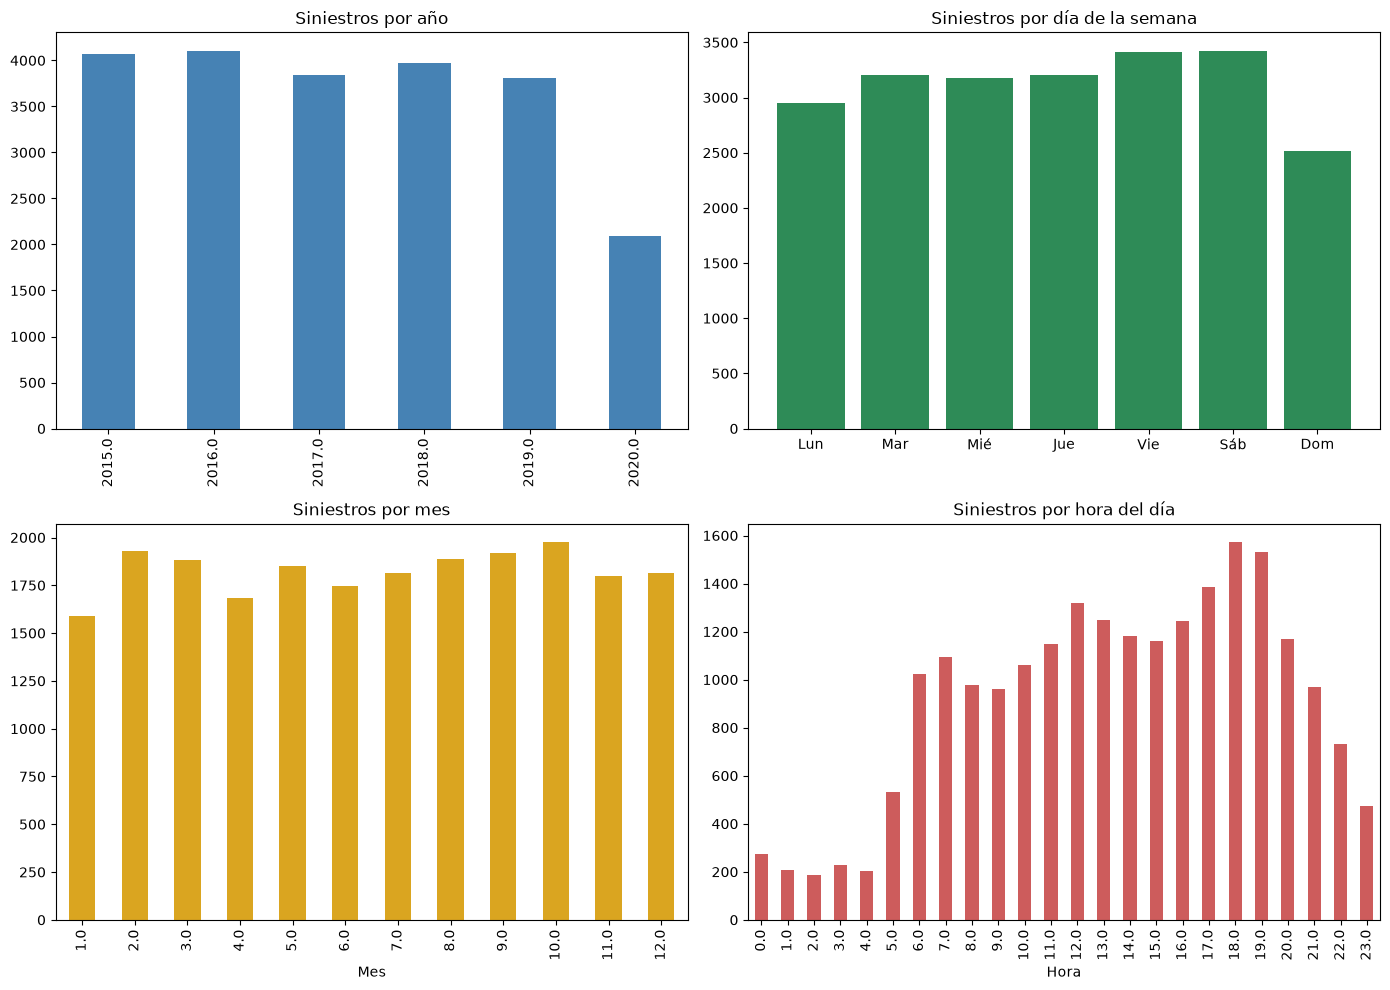

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

df['ANO_OCURRENCIA_ACC'].value_counts().sort_index().plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Siniestros por año')
axes[0,0].set_xlabel('')

orden_dias = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
etiquetas_dias = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']
conteo_dias = df['DIA_SEMANA'].value_counts().reindex(orden_dias)
axes[0,1].bar(etiquetas_dias, conteo_dias.values, color='seagreen')
axes[0,1].set_title('Siniestros por día de la semana')

df['MES'].value_counts().sort_index().plot(kind='bar', ax=axes[1,0], color='goldenrod')
axes[1,0].set_title('Siniestros por mes')
axes[1,0].set_xlabel('Mes')

df['HORA_DIA'].value_counts().sort_index().plot(kind='bar', ax=axes[1,1], color='indianred')
axes[1,1].set_title('Siniestros por hora del día')
axes[1,1].set_xlabel('Hora')

plt.tight_layout()
plt.show()

**Nota:** el pico visible en el gráfico "Siniestros por año" en los últimos años puede estar afectado por el hecho de que la hoja `SINIESTROS` del Excel solo cubre hasta 2020, mientras que el CSV llega hasta 2021; esto se refleja en el porcentaje de nulos de las columnas `CHOQUE`, `OBJETO_FIJO` y `DISENO_LUGAR` para 2021.

In [32]:
tabla_cobertura = df.groupby('ANO_OCURRENCIA_ACC')['DISENO_LUGAR'].apply(lambda s: s.notna().mean() * 100).round(1)
tabla_cobertura.to_frame('pct_con_match_en_SINIESTROS')

,pct_con_match_en_SINIESTROS
ANO_OCURRENCIA_ACC,
2015.0,100.0
2016.0,100.0
2017.0,100.0
2018.0,100.0
2019.0,100.0
2020.0,100.0


## 6. Gravedad, clase de siniestro, causas y actores

### 6.0 Distribución de la variable objetivo: peatones vs. total de siniestros

Antes de mirar la gravedad solo dentro del subconjunto peatonal, vale comparar contra la distribución general (capturada en la sección 3.8, antes del filtro) — esto además cuantifica algo que hasta ahora solo habíamos afirmado cualitativamente: si los siniestros con peatón son, en efecto, más severos que el promedio.


In [33]:
df['ESTADO'].value_counts()

ESTADO
HERIDO    22012
MUERTO     1433
ILESO         2
Name: count, dtype: int64

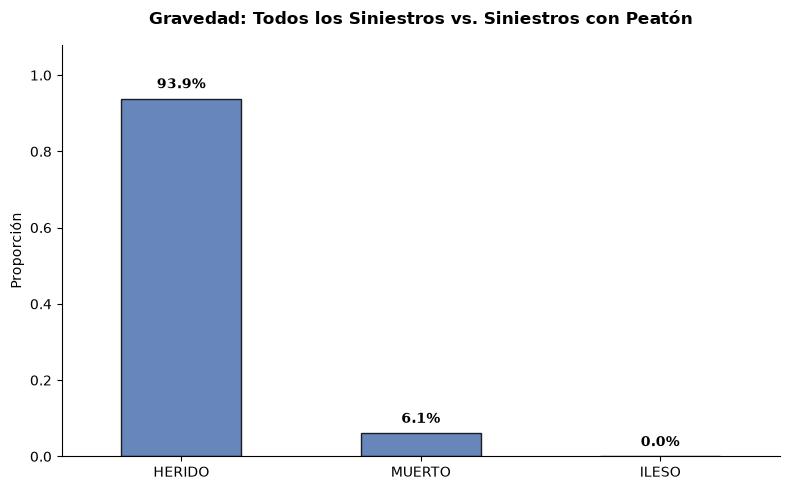

In [34]:
# 1. Crear la figura y el eje
fig, ax = plt.subplots(figsize=(8, 5))

# 2. Graficar las proporciones
s_estado = df['ESTADO'].value_counts(normalize=True)
s_estado.plot(kind='bar', ax=ax, color='#4C72B0', edgecolor='black', alpha=0.85)

# 3. Agregar los valores numéricos (porcentajes) sobre cada barra
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1%}',                   # Formato en porcentaje (ej: 85.2%)
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 5),                      # Desplazamiento vertical de 5pt
                textcoords="offset points",
                ha='center', va='bottom', 
                fontsize=10, fontweight='bold')

# 4. Personalizar el gráfico
ax.set_title('Gravedad: Todos los Siniestros vs. Siniestros con Peatón', fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel('Proporción', fontsize=10)
ax.set_xlabel('')
ax.set_ylim(0, max(s_estado.values) * 1.15)        # Margen superior para las etiquetas
plt.xticks(rotation=0)

# Ocultar bordes innecesarios
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

**Nota sobre desbalance de clases:** independientemente de cómo se compare contra el total, `GRAVEDAD` dentro de `df_peatones` normalmente estará dominada por `CON HERIDOS`, con `CON MUERTOS` como clase minoritaria. Esto es lo que justifica usar F1 macro/weighted y kappa ponderado (ya definidos en tu matriz metodológica) en vez de exactitud simple, y probablemente exija pesos de clase o remuestreo al entrenar el Random Forest.


### 6.1 Diseño del lugar y tipo de choque

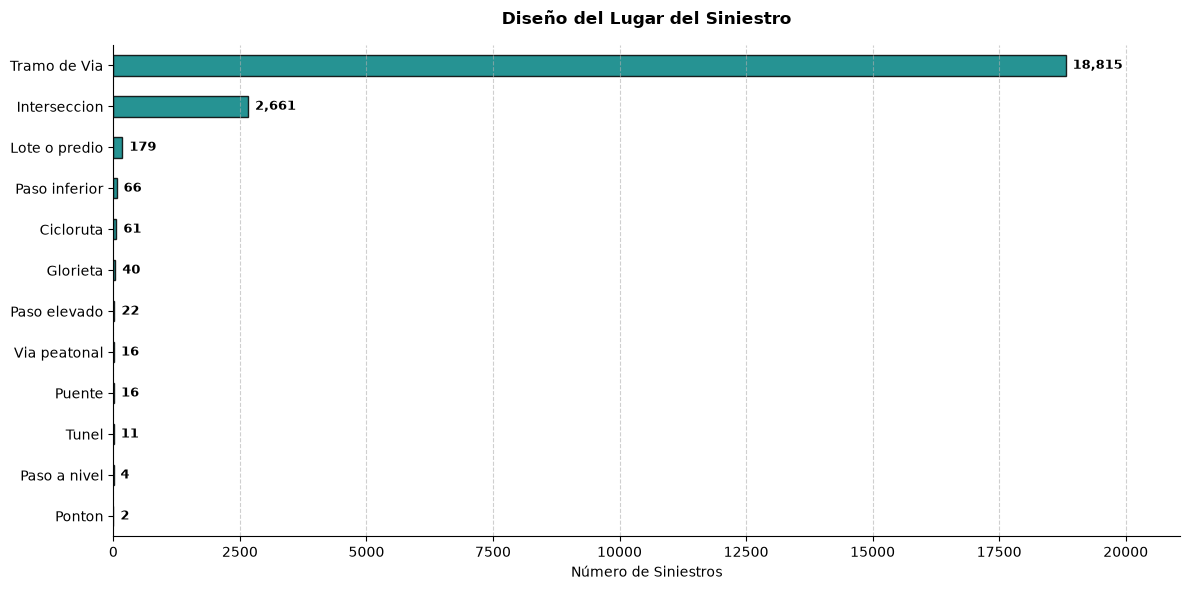

In [35]:
# 1. Al ser un solo panel (1,1), asignamos la variable como 'ax'
fig, ax = plt.subplots(figsize=(12, 6))

# 2. Obtener conteos
conteos = df['DISENO_LUGAR_DESC'].value_counts()

# 3. Graficar en el eje 'ax' (se invierte el orden para que la categoría mayor quede arriba)
bars = conteos.plot(kind='barh', ax=ax, color='teal', edgecolor='black', alpha=0.85)

# 4. Agregar etiquetas numéricas al final de cada barra horizontal
for bar in ax.patches:
    width = bar.get_width()
    if width > 0:
        ax.annotate(f'{int(width):,}',
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha='left', va='center', fontsize=9.5, fontweight='bold')

# 5. Personalización
ax.set_title('Diseño del Lugar del Siniestro', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Número de Siniestros', fontsize=10)
ax.set_ylabel('')
ax.invert_yaxis()  # Mantiene el valor más alto en la parte superior
ax.set_xlim(0, max(conteos.values) * 1.12)  # Margen derecho para las etiquetas

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 6.2 Causas principales de los siniestros

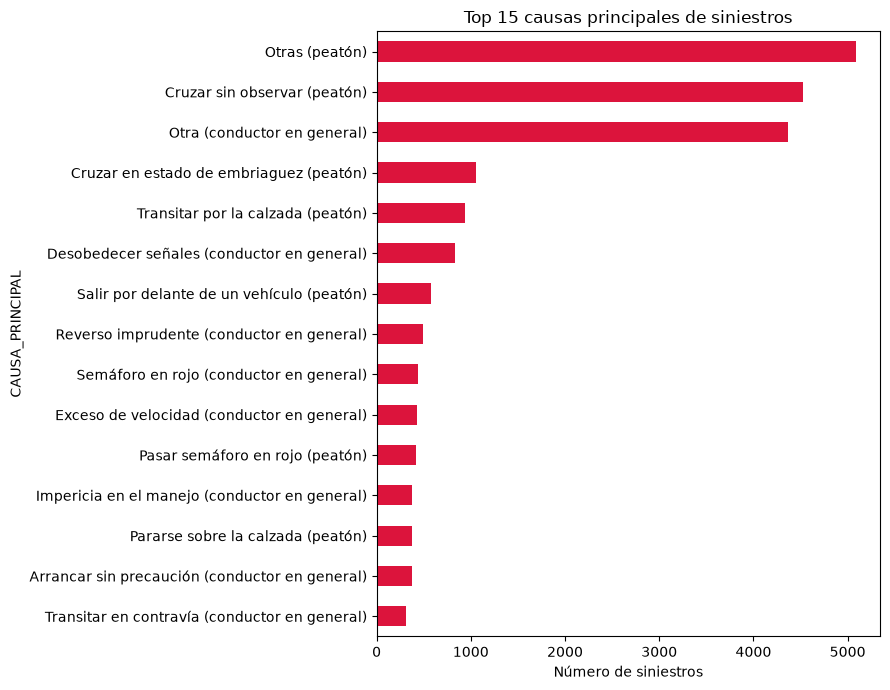

In [36]:
top_causas = df['CAUSA_PRINCIPAL'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9,7))
top_causas.sort_values().plot(kind='barh', ax=ax, color='crimson')
ax.set_title('Top 15 causas principales de siniestros')
ax.set_xlabel('Número de siniestros')
plt.tight_layout()
plt.show()

### 6.4 Siniestros por localidad

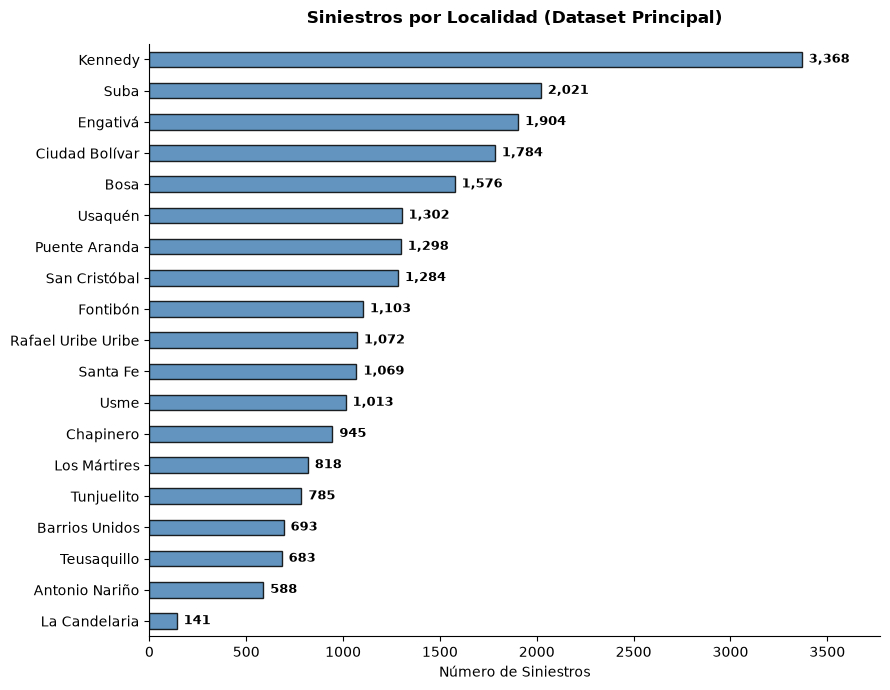

In [37]:
import matplotlib.pyplot as plt

# 1. Decodificar la localidad agregando la nueva columna 'LOCALIDAD_DESC' al DataFrame 'df'
df = decodificar(df, 'SINIESTROS', 'CODIGO_LOCALIDAD', 'LOCALIDAD_DESC')

# 2. Manejar posibles nulos si hay códigos no mapeados
df['LOCALIDAD_DESC'] = df['LOCALIDAD_DESC'].fillna('Sin Información')

# 3. Graficar usando 'df'
fig, ax = plt.subplots(figsize=(9, 7))
ax.set_axisbelow(True)
ax.grid(axis='x', linestyle='--', alpha=0.6)

conteos = df['LOCALIDAD_DESC'].value_counts().sort_values()
bars = conteos.plot(kind='barh', ax=ax, color='steelblue', edgecolor='black', alpha=0.85)

# 4. Anotar el conteo exacto al final de cada barra
for bar in ax.patches:
    width = bar.get_width()
    if width > 0:
        ax.annotate(f'{int(width):,}',
                    xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha='left', va='center', fontsize=9, fontweight='bold')

# 5. Personalizar títulos y límites
ax.set_title('Siniestros por Localidad (Dataset Principal)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Número de Siniestros', fontsize=10)
ax.set_ylabel('')
ax.set_xlim(0, max(conteos.values) * 1.12)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### 6.5 Gravedad por localidad (tabla cruzada)

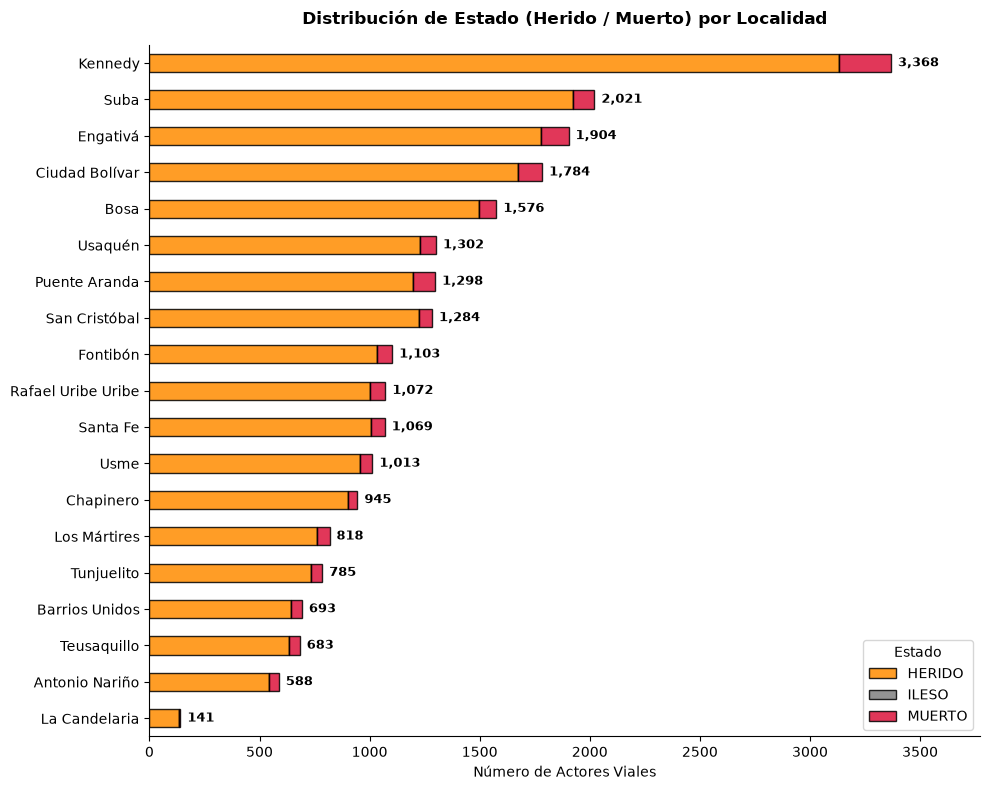

In [38]:
# 1. Generar y ordenar la tabla cruzada
tabla_grav_loc = pd.crosstab(df['LOCALIDAD_DESC'], df['ESTADO'])
tabla_grav_loc['TOTAL'] = tabla_grav_loc.sum(axis=1)

# Ordenar de mayor a menor según el TOTAL para el gráfico
tabla_ordenada = tabla_grav_loc.sort_values('TOTAL', ascending=True).drop(columns=['TOTAL'])

# 2. Configurar la figura para barras horizontales apiladas
fig, ax = plt.subplots(figsize=(10, 8))
ax.set_axisbelow(True)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Definir colores para cada estado
colores = {'HERIDO': 'darkorange', 'MUERTO': 'crimson'}
colores_list = [colores.get(col, 'gray') for col in tabla_ordenada.columns]

# 3. Graficar barras apiladas
bars = tabla_ordenada.plot(kind='barh', stacked=True, ax=ax, color=colores_list, edgecolor='black', alpha=0.85)

# 4. Anotar el total exacto al final de cada barra
for i, (idx, row) in enumerate(tabla_ordenada.iterrows()):
    total = row.sum()
    if total > 0:
        ax.annotate(f'{total:,}',
                    xy=(total, i),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha='left', va='center', fontsize=9, fontweight='bold')

# 5. Personalización del gráfico
ax.set_title('Distribución de Estado (Herido / Muerto) por Localidad', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('Número de Actores Viales', fontsize=10)
ax.set_ylabel('')
ax.set_xlim(0, tabla_grav_loc['TOTAL'].max() * 1.12)
ax.legend(title='Estado', frameon=True, loc='lower right')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### 6.7 Asociación entre variables categóricas y `GRAVEDAD` (Chi-cuadrado y Cramér's V)

Antes de que Boruta decida por su cuenta dentro del CV espacial, conviene ver qué categóricas muestran asociación con la severidad. Se usa Cramér's V (no solo el p-valor) porque con este volumen de datos casi cualquier asociación sale "significativa"; V mide qué tan fuerte es esa asociación, no solo si existe.


In [39]:
df.columns

Index(['CODIGO_ACCIDENTE', 'CODIGO_ACCIDENTADO', 'FECHA', 'CONDICION',
       'ESTADO', 'EDAD', 'SEXO', 'VEHICULO', 'CAUSA_PRINCIPAL',
       'CODIGO_LOCALIDAD', 'DISENO_LUGAR', 'DIRECCION', 'HORA', 'CLASE',
       'LATITUD', 'LONGITUD', 'DISENO_LUGAR_DESC', 'FECHA_OCURRENCIA_ACC',
       'ANO_OCURRENCIA_ACC', 'FECHA_HORA_ACC', 'MES', 'DIA_SEMANA', 'HORA_DIA',
       'LOCALIDAD_DESC'],
      dtype='str')

In [40]:
def cramers_v(tabla):
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    r, k = tabla.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

candidatas_categoricas = [
 'CONDICION', 'SEXO',
    'LOCALIDAD_DESC', 'DISENO_LUGAR_DESC', 'CLASE',
    'DIA_SEMANA', 'MES', 'HORA_DIA',
]

resultados = []
for col in candidatas_categoricas:
    if col not in df.columns:
        continue
    tabla = pd.crosstab(df[col], df['ESTADO'])
    tabla = tabla.loc[tabla.sum(axis=1) >= 5]  # descartar categorías con muy pocos casos
    if tabla.shape[0] < 2:
        continue
    chi2, p, dof, _ = chi2_contingency(tabla)
    v = cramers_v(tabla)
    resultados.append({'variable': col, 'chi2': chi2, 'p_valor': p, 'cramers_v': v, 'n_categorias': tabla.shape[0]})

tabla_bivariado_cat = pd.DataFrame(resultados).sort_values('cramers_v', ascending=False)
tabla_bivariado_cat


,variable,chi2,p_valor,cramers_v,n_categorias
0,SEXO,601.257017,8.282664e-129,0.113233,3
2,DISENO_LUGAR_DESC,191.448808,5.099672e-31,0.066133,10
6,HORA_DIA,186.410716,8.193564e-19,0.065248,24
1,LOCALIDAD_DESC,52.457841,3.752103e-02,0.033446,19
3,CLASE,46.130574,2.244920e-07,0.031364,5
5,MES,27.099392,2.074758e-01,0.024878,12
4,DIA_SEMANA,9.694939,6.427037e-01,0.014880,7


Como referencia orientativa para Cramér's V con 2-3 grados de libertad: <0.10 asociación despreciable, 0.10-0.30 débil, 0.30-0.50 moderada, >0.50 fuerte. Las variables con V muy bajo son candidatas a descartarse antes incluso de Boruta; ninguna decisión aquí es definitiva sin correrlo sobre los datos reales.


### 6.8 Asociación entre variables continuas y `GRAVEDAD` (Kruskal-Wallis)

Se usa Kruskal-Wallis (no ANOVA) porque no hay razón para asumir normalidad ni varianzas iguales entre los tres grupos de gravedad. Esta prueba es además la que debe decidir empíricamente si `EDAD_PEATON_MIN` (o alguna alternativa) es la que más separa a los grupos de gravedad, en vez de asumirlo.


EDAD: H=435.53, p-valor=2.661e-95
HORA_DIA: H=0.34, p-valor=0.8454


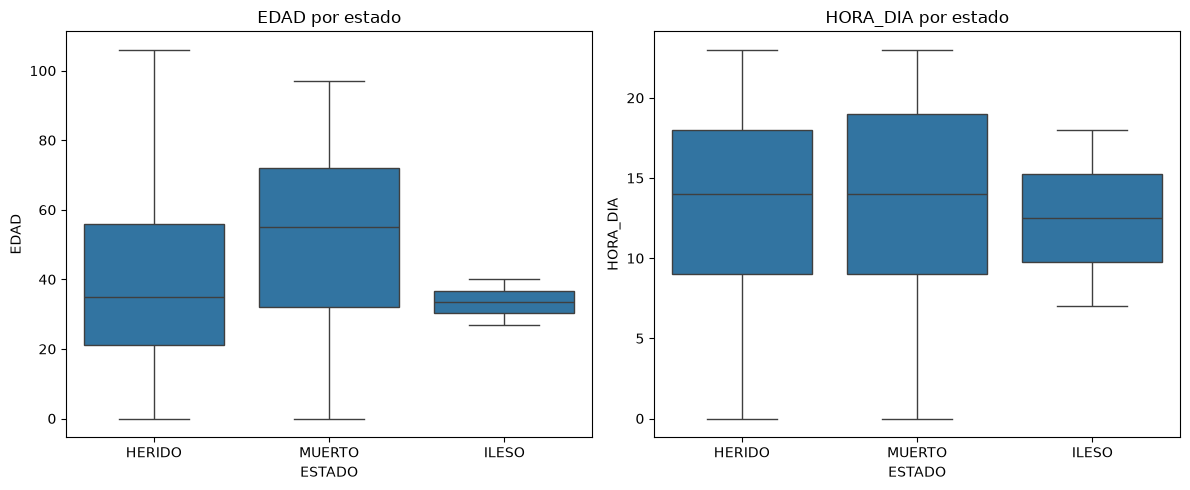

In [41]:
candidatas_continuas = ['EDAD', 'HORA_DIA']

for col in candidatas_continuas:
    # dropna por grupo: kruskal no tolera NaN dentro de los arrays de entrada
    grupos = [g.dropna().values for _, g in df.groupby('ESTADO')[col]]
    grupos = [g for g in grupos if len(g) > 0]
    if len(grupos) < 2:
        continue
    stat, p = kruskal(*grupos)
    print(f"{col}: H={stat:.2f}, p-valor={p:.4g}")

fig, axes = plt.subplots(1, len(candidatas_continuas), figsize=(6*len(candidatas_continuas), 5))
for ax, col in zip(np.atleast_1d(axes), candidatas_continuas):
    sns.boxplot(data=df, x='ESTADO', y=col, ax=ax)  # ESTADO, no GRAVEDAD: ver nota abajo
    ax.set_title(f'{col} por estado')
plt.tight_layout()
plt.show()


### 6.9 Multicolinealidad entre predictores numéricos candidatos

Diagnóstico previo a Boruta: correlación simple y, si `statsmodels` está disponible, VIF. `N_MUERTOS`/`N_HERIDOS`/`N_PEATONES_*` se excluyen deliberadamente de esta tabla — ya quedaron fuera del conjunto de predictores en la sección 6.6.


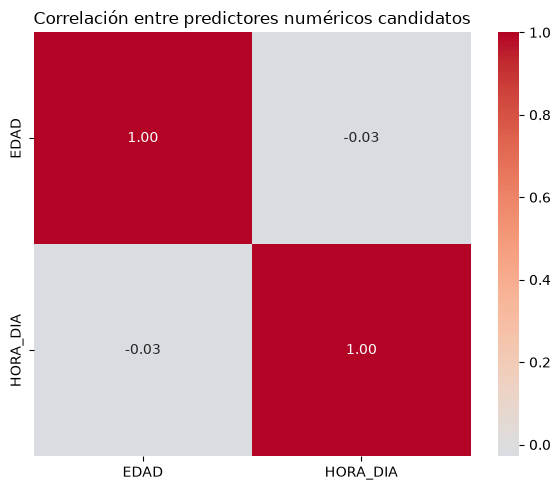

   variable       VIF
0      EDAD  2.795905
1  HORA_DIA  2.795905


In [42]:
numericas_candidatas = ['EDAD', 'HORA_DIA']
numericas_candidatas = [c for c in numericas_candidatas if c in df.columns]

corr = df[numericas_candidatas].corr()
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlación entre predictores numéricos candidatos')
plt.tight_layout()
plt.show()

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    X = df[numericas_candidatas].dropna()
    vif = pd.DataFrame({
        'variable': numericas_candidatas,
        'VIF': [variance_inflation_factor(X.values, i) for i in range(len(numericas_candidatas))]
    })
    print(vif)
except ImportError:
    print("statsmodels no está disponible en este entorno; instalar con `pip install statsmodels` para calcular VIF.")


## 7. Mapa de zonas con siniestros que involucran peatones

Se usan las coordenadas `LATITUD`/`LONGITUD` del CSV (presentes en el 100% de los registros) para construir:

1. Un mapa de puntos coloreado por gravedad.
2. Un mapa de densidad (hexbin) que resalta las **zonas con mayor concentración de siniestros**.
3. Un mapa de densidad exclusivo para siniestros **con muertos**, al ser el subconjunto de mayor interés para política pública.

In [43]:
coords_validas = df[['LATITUD','LONGITUD']].notna().all(axis=1).sum()
print(f"Registros con coordenadas válidas: {coords_validas:,} de {len(df):,} ({coords_validas/len(df)*100:.1f}%)")
print()
print(df[['LATITUD','LONGITUD']].describe())

Registros con coordenadas válidas: 21,893 de 23,447 (93.4%)

            LATITUD      LONGITUD
count  21893.000000  21893.000000
mean       4.632386    -74.113450
std        0.062406      0.040477
min        4.085800    -74.228300
25%        4.589411    -74.143267
50%        4.624097    -74.112000
75%        4.678424    -74.084536
max        4.818734    -74.014053


### 7.0 Recorte a la zona urbana

Un pequeño número de registros (~13 de 199.146) tiene coordenadas muy alejadas del área urbana de Bogotá (zonas rurales del sur / posibles errores de geocodificación). Al graficarlos, estiran la escala del mapa y dificultan ver el detalle de la ciudad. Se acotan los ejes a la zona urbana para los mapas siguientes; el dataset `df` **no se filtra**, solo se ajusta la vista.

In [44]:
LON_MIN, LON_MAX = -74.24, -73.99
LAT_MIN, LAT_MAX = 4.45, 4.84

fuera_de_rango = (~df['LONGITUD'].between(LON_MIN, LON_MAX)) | (~df['LATITUD'].between(LAT_MIN, LAT_MAX))
print(f"Registros fuera de la zona urbana acotada: {fuera_de_rango.sum()} de {len(df)}")

Registros fuera de la zona urbana acotada: 1555 de 23447


### 7.1 Mapa de puntos por gravedad

In [48]:
print(df['ESTADO'].value_counts(dropna=False))

ESTADO
HERIDO    22012
MUERTO     1433
ILESO         2
Name: count, dtype: int64


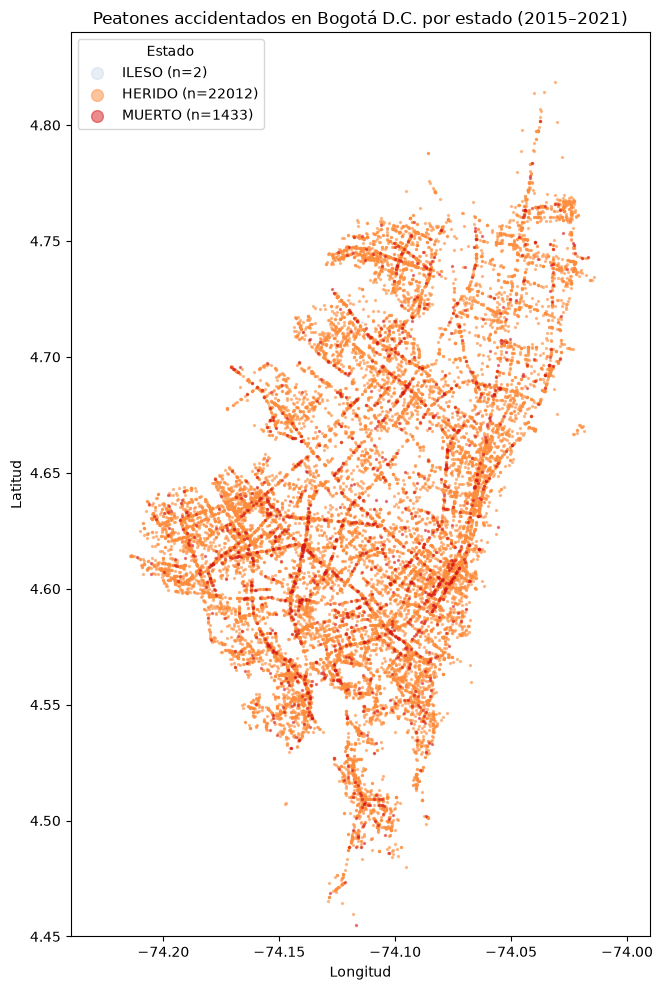

In [49]:
fig, ax = plt.subplots(figsize=(9, 10))

# Orden de dibujo: ILESO y HERIDO como fondo, MUERTO al final para que quede visible
# encima en zonas de alta densidad de puntos. Valores confirmados con value_counts()
# el 2026-09-17: HERIDO=22012, MUERTO=1433, ILESO=2 (categoría casi residual).
orden_plot = ['ILESO', 'HERIDO', 'MUERTO']
colores = {'ILESO': '#a6bddb', 'HERIDO': '#fd8d3c', 'MUERTO': '#d7191c'}

for grav in orden_plot:
    sub = df[df['ESTADO'] == grav]
    if sub.empty:
        print(f'ADVERTENCIA: sin registros para "{grav}"')
        continue
    ax.scatter(sub['LONGITUD'], sub['LATITUD'], s=2,
               alpha=0.25 if grav == 'ILESO' else 0.5,
               color=colores[grav], label=f'{grav} (n={len(sub)})')  # n en la leyenda: ILESO=2 necesita quedar visible como dato, no solo como punto invisible

ax.set_title('Peatones accidentados en Bogotá D.C. por estado (2015–2021)')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(markerscale=6, title='Estado')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

### 7.2 Mapa de densidad (zonas con mayor concentración de siniestros)

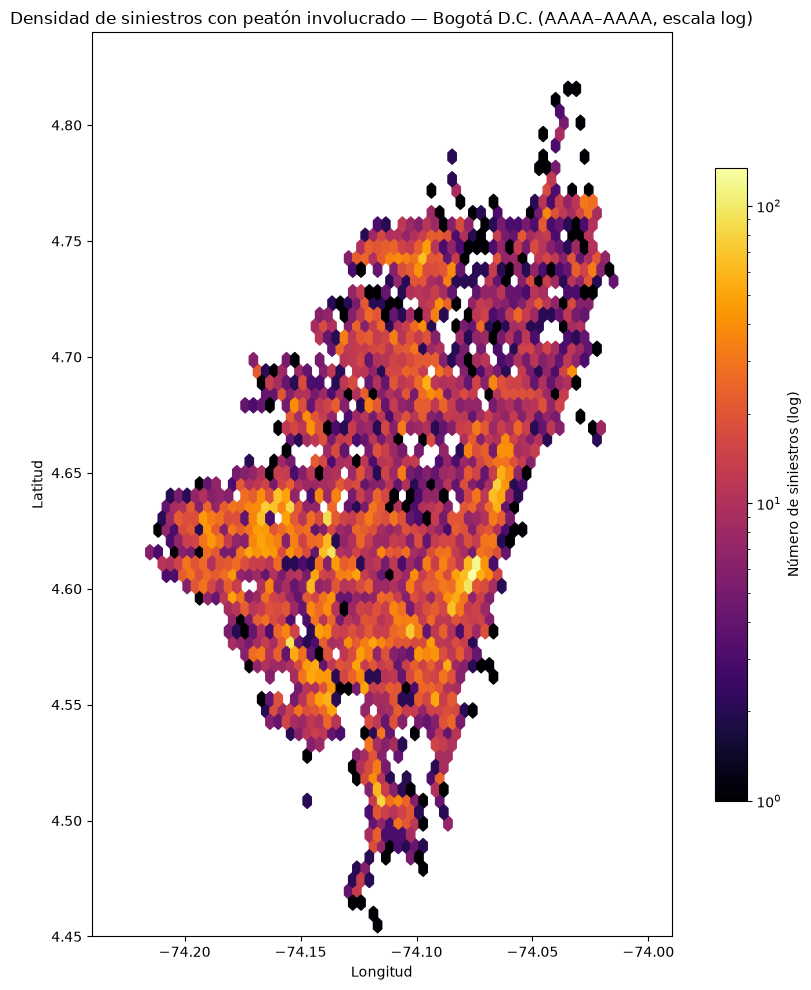

In [ ]:
fig, ax = plt.subplots(figsize=(9, 10))

hb = ax.hexbin(df['LONGITUD'], df['LATITUD'], gridsize=70, cmap='inferno', mincnt=1, bins='log',
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
# Placeholder de años: reemplaza con el rango real confirmado vía ANO_OCURRENCIA_ACC.min()/.max()
ax.set_title('Densidad de siniestros con peatón involucrado — Bogotá D.C.')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros (log)')
plt.tight_layout()
plt.show()

### 7.3 Mapa de densidad — solo siniestros con muertos

Siniestros con muertos: 1,433


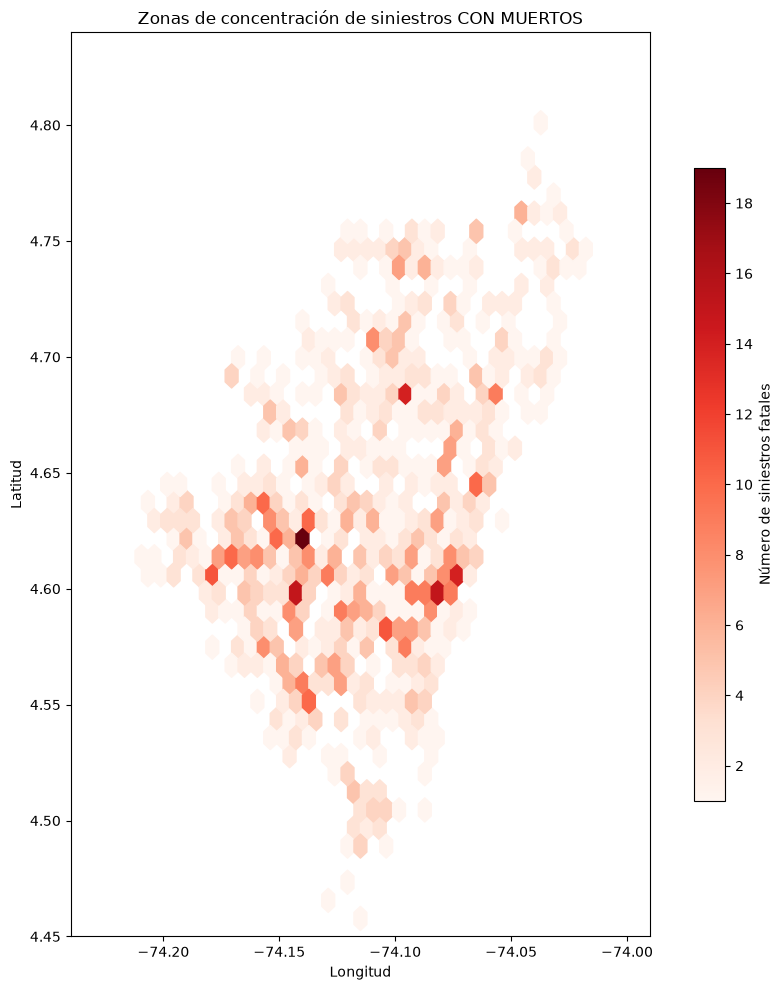

In [51]:
fatales = df[df['ESTADO'] == 'MUERTO']
print(f"Siniestros con muertos: {len(fatales):,}")

fig, ax = plt.subplots(figsize=(9, 10))
hb = ax.hexbin(fatales['LONGITUD'], fatales['LATITUD'], gridsize=45, cmap='Reds', mincnt=1,
               extent=(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX))
ax.set_title('Zonas de concentración de siniestros CON MUERTOS')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.set_xlim(LON_MIN, LON_MAX)
ax.set_ylim(LAT_MIN, LAT_MAX)
ax.set_aspect('equal')
cb = fig.colorbar(hb, ax=ax, shrink=0.7)
cb.set_label('Número de siniestros fatales')
plt.tight_layout()
plt.show()

### 7.4 Top 10 direcciones con más siniestros

Complementa el mapa identificando los puntos exactos (direcciones) más críticos.

In [52]:
df['DIRECCION'].value_counts().head(10).to_frame('N_SINIESTROS')

,N_SINIESTROS
DIRECCION,
KR 80-CL 2 51,43
AV AVENIDA CARACAS-CL 22 02,24
KR 80-CL 2 S 51,21
AV AVENIDA CARACAS-CL 40 S 02,18
KR 10-CL 13 02,17
AV AVENIDA CARACAS-CL 60 02,16
AV AVENIDA BOYACA-AV AVENIDA PRIMERO DE MAYO 02,14
AV AVENIDA BOYACA-CL 53 02,14
AV AVENIDA CARACAS-CL 6 02,13


## 8. Resumen y hallazgos clave



## 9. Salida final

In [ ]:
import geopandas as gpd
df = gpd.GeoDataFrame(
    df,  # o el DataFrame que estés procesando
    geometry=gpd.points_from_xy(df.LONGITUD, df.LATITUD),  # Cambia por los nombres exactos de tus columnas
    crs="EPSG:3116"
)

print("Nulos en geometry (siniestraliedad):", df.geometry.isna().sum())

In [ ]:
s.makedirs('Data/processed', exist_ok=True)
df.to_file('Data/processed/siniestros_procesados.gpkg', driver='GPKG')

print('Guardado: Data/processed/peatonal_procesada.gpkg', df.shape)